# PCR vs PLS regression — *Communities and Crime* data

**Goal of the project.** Explain, for a non-expert reader, what Partial Least Squares (PLS) regression does and how it differs from
Principal Components Regression (PCR), using one real data set with many correlated predictors.

**The one-sentence answer we will illustrate.** Both methods replace the 100 original predictors by a few *components*
(linear combinations of the predictors) and regress the response on them. **PCR builds its components by looking only at $X$**
(directions of maximum variance), **PLS builds them by looking at $X$ *and* $y$** (directions of maximum covariance with the response).

**Code conventions.** The code follows the course notebooks (Chapter 1: PCA by eigen-decomposition of the correlation matrix;
Chapter 2: standardized $X$, centered $Y$, ridge and PCR written with the SVD of $X$) and the PLS algorithm of the slides by
G. Sanchez. scikit-learn is only used to *check* that our hand-written code gives the right numbers.

### Roadmap

| Part | Sections | What it does |
|---|---|---|
| **I. Data** | 1–4 | Load and clean the data; show that the predictors are strongly correlated (why PCR/PLS make sense here) |
| **II. The two methods, step by step** | 5–8 | Standardize; PCR with the SVD (course formulas); PLS with the slides' algorithm; compare what each one maximises |
| **III. Honest comparison of predictions** | 9–12 | Explain the cross-validation by **groups of states**; choose the number of components; measure the error on states never seen |
| **IV. When and why they differ** | 13–14 | Effect of the sample size; interpretation of components and coefficients |
| **V. Robustness** | 15–16 | Without the race variables; 20 different splits of the states |
| **VI. Conclusion** | 17–18 | Summary table, take-aways and limits |

---
# Part I — Data

## 1. Libraries and settings

Same libraries as in the course notebooks. Two global choices:

- `K_MAX = 40`: we try PCR and PLS with $k = 1, 2, \dots, 40$ components (beyond 40 nothing changes on this data set).
- `LAMBDAS`: the grid of penalties for the ridge regression, used as a *benchmark* (ridge is the other "shrinkage" method of Chapter 2).

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.linalg import eig, inv, svd

from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.cross_decomposition import PLSRegression   # only used to CHECK our own PLS code
from sklearn.decomposition import PCA                    # only used to CHECK our own PCR code
from sklearn.linear_model import LinearRegression        # only used to CHECK our own PCR code

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = [10, 5]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

# Colours used in every figure
C_PCR, C_PLS, C_RIDGE, C_OLS, C_MEAN = "#1f77b4", "#e07b00", "#2a9d5c", "#8c564b", "#888888"

SEED = 0
K_MAX = 40                            # numbers of components tried: 1, ..., 40
LAMBDAS = np.logspace(-2, 5, 60)      # ridge penalties tried (benchmark)
N_FOLDS = 5                           # 5 folds of STATES (see Section 9)

## 2. Loading the data

**Source.** UCI Machine Learning Repository, *Communities and Crime* (Redmond & Baveja, 2002), licence CC BY 4.0.
It combines the 1990 US Census, the 1990 LEMAS police survey and the 1995 FBI crime statistics.

- **1 994 communities** (cities/towns) in **46 states**.
- **128 columns**: 5 identifiers, 122 socio-economic predictors, and the response `ViolentCrimesPerPop`
  (violent crimes per 100 000 inhabitants).
- Every numeric variable has already been **normalized to [0, 1]** by the authors. So a value of 0.5 means "in the middle of the range of
  that variable", not "50 %".
- Missing values are coded `?`.

The two files `communities.data` (the values) and `communities.names` (the description, from which we read the column names)
must be in the same folder as this notebook.

In [2]:
DATA_FILE = Path("/content/communities.data")
NAMES_FILE = Path("/content/communities.names")
if not (DATA_FILE.exists() and NAMES_FILE.exists()):
    raise FileNotFoundError("Put communities.data and communities.names in the same folder as this notebook.")

# Column names: the .names file contains one line '@attribute <name> <type>' per column
names = [m.group(1) for line in NAMES_FILE.read_text(errors="ignore").splitlines()
         if (m := re.match(r"@attribute\s+(\S+)", line))]

df = pd.read_csv(DATA_FILE, header=None, na_values="?")
df.columns = names

print("Shape of the data:", df.shape)
df.head()

Shape of the data: (1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


## 3. Cleaning

Three decisions, each explained:

1. **Drop the 5 identifiers** (`state`, `county`, `community`, `communityname`, `fold`): they are not predictors.
   We keep `state` aside in a vector `groups`: it will be used to split the data **by state** (Section 9).
2. **Drop the 22 police variables (LEMAS)**: they are missing for 1 675 of the 1 994 communities (84 %).
   Keeping them would force us to throw away 84 % of the rows.
3. **One remaining missing value** (`OtherPerCap`, one community). It is replaced by the median of the variable.
   In Parts III–V this is done *inside each training sample* (the median is computed without looking at the test data).

We end up with **1 994 communities × 100 predictors**.

In [3]:
ID_COLS = ["state", "county", "community", "communityname", "fold"]
TARGET = "ViolentCrimesPerPop"

groups = df["state"].to_numpy()                 # state of each community (used for the grouped cross-validation)
Y = df[TARGET]
X_all = df.drop(columns=ID_COLS + [TARGET])

share_missing = X_all.isna().mean()
lemas_cols = share_missing[share_missing > 0.5].index.tolist()
X = X_all.drop(columns=lemas_cols)
FEATURES = X.columns.tolist()

print(f"Police (LEMAS) variables dropped: {len(lemas_cols)}")
print(f"Remaining missing values: {int(X.isna().sum().sum())} (in {X.columns[X.isna().any()].tolist()})")
print(f"Final data: n = {X.shape[0]} communities, p = {X.shape[1]} predictors, {len(np.unique(groups))} states")

Police (LEMAS) variables dropped: 22
Remaining missing values: 1 (in ['OtherPerCap'])
Final data: n = 1994 communities, p = 100 predictors, 46 states


count    1994.000
mean        0.238
std         0.233
min         0.000
25%         0.070
50%         0.150
75%         0.330
max         1.000
Name: ViolentCrimesPerPop, dtype: float64


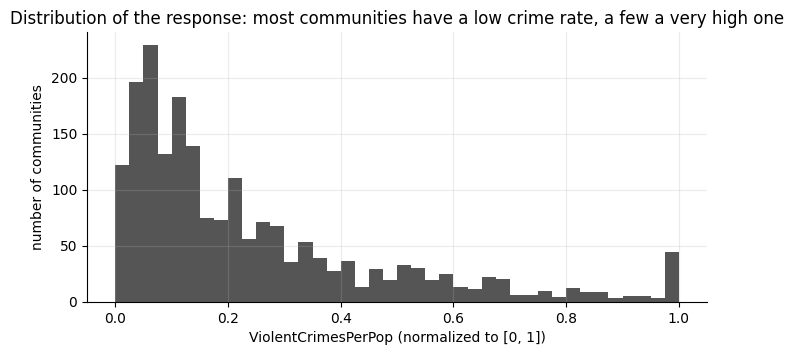

In [4]:
# The response variable
print(Y.describe().round(3))

plt.figure(figsize=(8, 3.5))
plt.hist(Y, bins=40, color="#555")
plt.xlabel("ViolentCrimesPerPop (normalized to [0, 1])"); plt.ylabel("number of communities")
plt.title("Distribution of the response: most communities have a low crime rate, a few a very high one")
plt.show()

## 4. Why PCR and PLS make sense here: the predictors are strongly correlated

PCR and PLS are useful when the predictors are **many and redundant** (multicollinearity). Then OLS coefficients become unstable
(large variance, sometimes signs that contradict the correlations — see the *cars2004* example of the slides).

We check this exactly as in the Chapter 1 notebooks: **eigen-decomposition of the correlation matrix**, eigenvalues sorted in
decreasing order, proportion of variance explained by each principal component.

How to read the results:
- if a few eigenvalues are large and many are close to 0, a few components summarise most of the information → good case for PCR/PLS;
- the ratio between the largest and the smallest eigenvalue (the *condition number*) measures how unstable OLS is
  (Chapter 2 notebooks `Smallest_eigvalue_*`).

In [5]:
# Median imputation of the single missing value (for the descriptive part only)
X_filled = X.fillna(X.median())
n, p = X_filled.shape

# Computation of the correlation matrix
corr_matrix = X_filled.corr()

# Computation of eigenvalues and eigenvectors, then sort them (as in the course)
l, e = eig(corr_matrix)
idx = l.real.argsort()[::-1]
l, e = l.real[idx], e.real[:, idx]

# Computation of the proportion of variance explained by each principal component
Proportion_var_expl_PC = l / sum(l)
cum_var = np.cumsum(Proportion_var_expl_PC)

print("Proportion of variance explained by PC1 to PC5:", np.round(Proportion_var_expl_PC[:5], 3))
for q in (0.80, 0.90, 0.95):
    print(f"Number of components needed for {q:.0%} of the variance: {np.searchsorted(cum_var, q) + 1} (out of p = {p})")
print(f"Largest eigenvalue = {l[0]:.2f} | smallest eigenvalue = {l[-1]:.5f} | condition number sqrt(l_max/l_min) = {np.sqrt(l[0]/l[-1]):.0f}")

Proportion of variance explained by PC1 to PC5: [0.252 0.168 0.093 0.076 0.056]
Number of components needed for 80% of the variance: 11 (out of p = 100)
Number of components needed for 90% of the variance: 23 (out of p = 100)
Number of components needed for 95% of the variance: 35 (out of p = 100)
Largest eigenvalue = 25.18 | smallest eigenvalue = 0.00063 | condition number sqrt(l_max/l_min) = 200


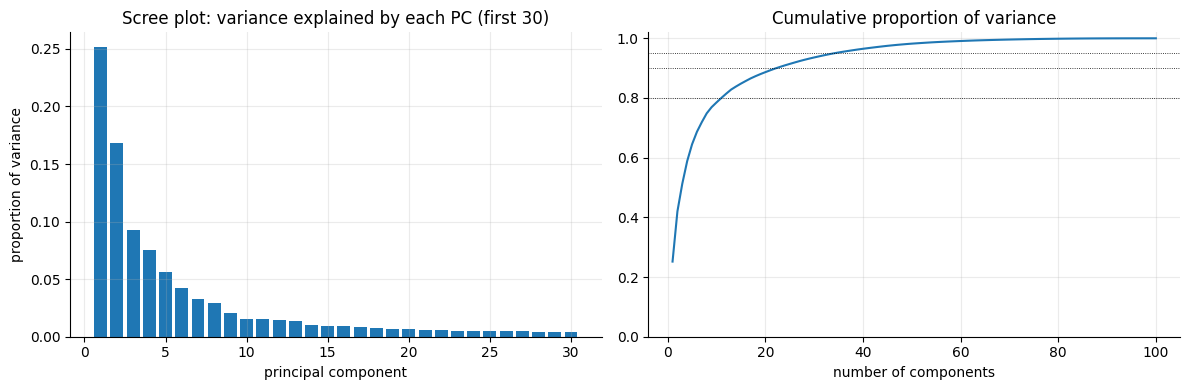

Share of pairs with |correlation| > 0.7: 4.8% (4950 pairs)

The 10 most correlated pairs:
     variable 1        variable 2  correlation
   PctRecImmig8     PctRecImmig10        0.996
 OwnOccLowQuart      OwnOccMedVal        0.994
   PctRecImmig5      PctRecImmig8        0.993
     population         numbUrban        0.993
   OwnOccMedVal     OwnOccHiQuart        0.991
 PctRecentImmig      PctRecImmig5        0.989
     RentMedian           MedRent        0.989
   PctRecImmig5     PctRecImmig10        0.986
     PctFam2Par       PctKids2Par        0.985
PctLargHouseFam PctLargHouseOccup        0.984

The 10 predictors most correlated with the response:
PctKids2Par        -0.738
PctIlleg            0.738
PctFam2Par         -0.707
racePctWhite       -0.685
PctYoungKids2Par   -0.666
PctTeen2Par        -0.662
racepctblack        0.631
pctWInvInc         -0.576
pctWPubAsst         0.575
FemalePctDiv        0.556


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, 31), Proportion_var_expl_PC[:30], color=C_PCR)
ax[0].set(title="Scree plot: variance explained by each PC (first 30)", xlabel="principal component", ylabel="proportion of variance")
ax[1].plot(range(1, p + 1), cum_var, color=C_PCR)
for q in (0.8, 0.9, 0.95):
    ax[1].axhline(q, color="k", lw=.6, ls=":")
ax[1].set(title="Cumulative proportion of variance", xlabel="number of components", ylim=(0, 1.02))
plt.tight_layout(); plt.show()

# The most correlated pairs of predictors
iu = np.triu_indices(p, 1)
pairs = pd.DataFrame({"variable 1": np.array(FEATURES)[iu[0]], "variable 2": np.array(FEATURES)[iu[1]],
                      "correlation": corr_matrix.values[iu]})
print("Share of pairs with |correlation| > 0.7:", f"{(pairs.correlation.abs() > 0.7).mean():.1%}", f"({len(pairs)} pairs)")
print("\nThe 10 most correlated pairs:")
print(pairs.reindex(pairs.correlation.abs().sort_values(ascending=False).index).head(10).round(3).to_string(index=False))

# Correlation of each predictor with the response
corr_with_Y = X_filled.corrwith(Y)
print("\nThe 10 predictors most correlated with the response:")
print(corr_with_Y.reindex(corr_with_Y.abs().sort_values(ascending=False).index).head(10).round(3).to_string())

**Reading.** A handful of components summarise most of the 100 predictors (about 23 components for 90 % of the variance), many pairs
of variables are almost duplicates (e.g. the recent-immigration variables measured over 5, 8 and 10 years, or the median rent
measured in two ways) and the smallest eigenvalue is close to 0: this is exactly the multicollinearity situation described in the
introduction of the PLS slides. The variables most correlated with crime are mostly family-structure variables
(`PctKids2Par`: % of kids living with two parents; `PctIlleg`: % of kids born to never-married parents), race percentages and income/poverty variables.

---
# Part II — The two methods, step by step (on the whole sample)

In this part we fit the methods on **all** 1 994 communities to understand *how they work*. We do **not** measure prediction errors here:
an error measured on the data used for fitting is always too optimistic. Prediction errors come in Part III.

## 5. Standardization (as in the course)

As in `Ridge_Credit.ipynb`: **standardized $X$** (each column has mean 0 and variance 1) and **centered $Y$** (mean 0).

Why standardize? PCR and PLS work with variances and covariances. Without standardization a variable measured on a larger scale would
dominate the components just because of its unit. After standardization, $\frac{1}{n}X'X$ **is the correlation matrix**
of Section 4.

There is no intercept in the models on standardized data; the intercept comes back as the mean of $Y$ when predicting.

In [7]:
# Centered Y
mean_Y = Y.mean()
centered_Y = (Y - mean_Y).to_numpy()

# Standardized X (std with ddof=0 so that X'X/n is exactly the correlation matrix)
mean_X = X_filled.mean()
std_X = X_filled.std(ddof=0)
standardized_X = ((X_filled - mean_X) / std_X).to_numpy()

print("Means of the standardized X (should be 0):", np.abs(standardized_X.mean(0)).max().round(12))
print("Variances of the standardized X (should be 1):", np.round(standardized_X.var(0)[:5], 6), "...")
print("X'X/n equals the correlation matrix:", np.allclose(standardized_X.T @ standardized_X / n, corr_matrix.values))

Means of the standardized X (should be 0): 0.0
Variances of the standardized X (should be 1): [1. 1. 1. 1. 1.] ...
X'X/n equals the correlation matrix: True


## 6. PCR — Principal Components Regression (course, Chapter 2, slides 70–72)

**Idea.** Two stages:
1. **PCA on $X$ only** — find the directions in which the communities differ the most (maximum variance of $X$). The response is *not* used.
2. **OLS of $y$ on the first $k$ principal components.**

**Formulas of the course.** With the singular value decomposition $X = U D V'$:

- the principal directions are the columns of $V$ (the eigenvectors of the correlation matrix of Section 4);
- the $k$ first principal components (scores) are $Z_k = X V_k$;
- OLS of $y$ on $Z_k$: $\hat\gamma = (Z_k' Z_k)^{-1} Z_k' y$;
- back to the original variables: $\hat\beta^{PCR}_k = V_k\hat\gamma = V_k (D_k^2)^{-1} D_k U_k' y$;
- when $k = p$ (all components), $\hat\beta^{PCR}_k = \hat\beta^{OLS}$.

$k$ is a **hyperparameter** (like $\lambda$ for ridge): it is chosen by cross-validation in Part III.

### 6.1 The SVD of $X$ and its link with the PCA of Section 4

In [8]:
U, d, V_t = svd(standardized_X, full_matrices=False)    # X = U D V'   (numpy returns V' = V_t)
V = V_t.T

# The squared singular values divided by n are the eigenvalues of the correlation matrix (Section 4)
print("d^2 / n equals the eigenvalues of the correlation matrix:", np.allclose(d**2 / n, l))
print("First 5 values of d^2/n:", np.round(d[:5]**2 / n, 3))

d^2 / n equals the eigenvalues of the correlation matrix: True
First 5 values of d^2/n: [25.177 16.822  9.296  7.551  5.633]


### 6.2 PCR with $k = 3$ components, written exactly as in the course

In [9]:
k = 3
V_k = V[:, 0:k]

# Stage 1: the k first principal components (one score per community and per component)
Z_k = standardized_X @ V_k

# Stage 2: OLS of the centered Y on the components
gamma_hat = inv(Z_k.T @ Z_k) @ Z_k.T @ centered_Y

# Back to the original (standardized) predictors
beta_PCR = V_k @ gamma_hat

# Same thing with the closed form of slide 71: V_k (D_k^2)^-1 D_k U_k' y
D_k = np.diag(d[0:k])
beta_PCR_formula = V_k @ inv(D_k @ D_k) @ D_k @ U[:, 0:k].T @ centered_Y

print("gamma_hat (one coefficient per component):", np.round(gamma_hat, 4))
print("Both formulas give the same beta_PCR:", np.allclose(beta_PCR, beta_PCR_formula))

# Check against scikit-learn (PCA followed by OLS)
sk = LinearRegression().fit(PCA(n_components=k).fit_transform(standardized_X), centered_Y)
pred_sk = sk.predict(PCA(n_components=k).fit_transform(standardized_X))
print("Same predictions as scikit-learn PCA + LinearRegression:", np.allclose(standardized_X @ beta_PCR, pred_sk))

gamma_hat (one coefficient per component): [-0.0291  0.0155 -0.0148]
Both formulas give the same beta_PCR: True
Same predictions as scikit-learn PCA + LinearRegression: True


### 6.3 PCR for every $k$ at once

Because the principal components are **orthogonal**, the OLS coefficient of each component does not depend on the others:
$\hat\gamma_j = \dfrac{z_j'y}{z_j'z_j} = \dfrac{u_j'y}{d_j}$. So the PCR coefficients with $k$ components are just a **cumulative sum**:
$\hat\beta^{PCR}_k = \sum_{j=1}^{k} v_j\,\hat\gamma_j$. The function below returns them for $k = 1, \dots, K$ in one go (one column per $k$);
this makes the cross-validation of Part III fast.

In [10]:
def pcr_path(Xs, yc, K):
    # PCR coefficients for k = 1..K (matrix p x K). Xs: standardized X, yc: centered y.
    U, d, V_t = svd(Xs, full_matrices=False)
    gamma = (U.T @ yc) / d                         # OLS coefficient of each principal component
    return np.cumsum(V_t[:K].T * gamma[:K], axis=1)

B_pcr = pcr_path(standardized_X, centered_Y, p)
beta_OLS = np.linalg.lstsq(standardized_X, centered_Y, rcond=None)[0]
print("Column k=3 equals beta_PCR of 6.2:", np.allclose(B_pcr[:, 2], beta_PCR))
print("With k = p = 100 components, PCR = OLS:", np.allclose(B_pcr[:, -1], beta_OLS))

Column k=3 equals beta_PCR of 6.2: True
With k = p = 100 components, PCR = OLS: True


### 6.4 What do the first principal components represent? (correlation circle, as in Chapter 1)

As in `PCA_Hockey_dataset.ipynb`, the correlation between principal component $j$ and variable $x_m$ is
$e_{mj}\sqrt{\ell_j}$ (eigenvector × square root of the eigenvalue). Each dot is one of the 100 predictors; we label the 10 that are
best represented (skipping labels that would overlap: near-duplicate variables sit at the same place). The **red arrow** is the response $y$ (it is *not* used to build the components — it is only projected on them).

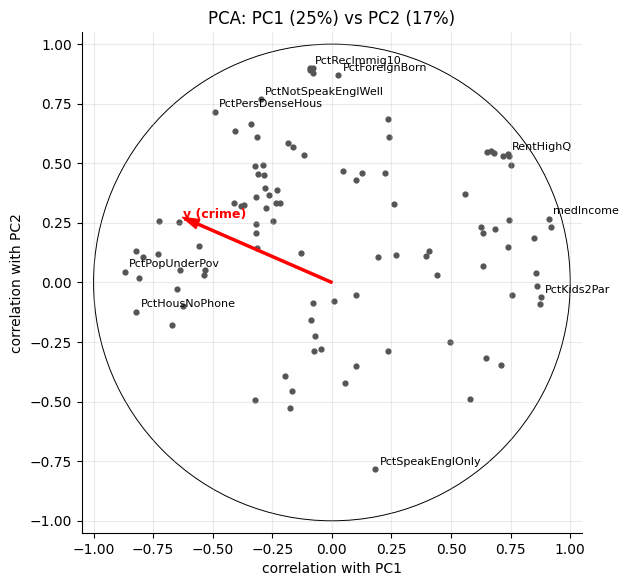

Correlation of the response with PC1 = -0.626, with PC2 = +0.273


In [11]:
def corr_circle(ax, C1, C2, cy, title, labels=FEATURES, n_lab=10):
    # Correlation circle: (C1, C2) = correlations of each predictor with the two components, cy = correlations of y with them
    ax.scatter(C1, C2, s=12, color="#555")
    ax.add_patch(plt.Circle((0, 0), 1, color="k", fill=False, lw=.7))
    placed = []                                    # label the best represented variables, skipping overlapping ones
    for i in np.argsort(-(C1**2 + C2**2)):
        if len(placed) == n_lab:
            break
        if all(np.hypot(C1[i] - a, C2[i] - b) > 0.12 for a, b in placed):
            ax.annotate(labels[i], (C1[i], C2[i]), fontsize=8, xytext=(3, 3), textcoords="offset points")
            placed.append((C1[i], C2[i]))
    ax.annotate("", xy=cy, xytext=(0, 0), arrowprops=dict(color="red", width=1.5, headwidth=7))
    ax.annotate("y (crime)", cy, color="red", fontsize=9, fontweight="bold")
    ax.set(xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), aspect="equal", title=title)

# Correlation between each PC and each feature: e * sqrt(l)  (course formula)
Corr_PC_X = e[:, :2] * np.sqrt(l[:2])
# Sign convention: same signs as the SVD
Corr_PC_X *= np.sign(np.sum(e[:, :2] * V[:, :2], axis=0))
corr_PC_Y = [np.corrcoef(standardized_X @ V[:, j], centered_Y)[0, 1] for j in range(2)]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
corr_circle(ax, Corr_PC_X[:, 0], Corr_PC_X[:, 1], corr_PC_Y,
            f"PCA: PC1 ({Proportion_var_expl_PC[0]:.0%}) vs PC2 ({Proportion_var_expl_PC[1]:.0%})")
ax.set(xlabel="correlation with PC1", ylabel="correlation with PC2"); plt.show()
print(f"Correlation of the response with PC1 = {corr_PC_Y[0]:+.3f}, with PC2 = {corr_PC_Y[1]:+.3f}")

## 7. PLS — Partial Least Squares regression (slides of G. Sanchez)

**Idea (slides 11–13).** Like PCR, PLS projects $y$ on a few uncorrelated components $Z = [z_1, \dots, z_k]$ that
- approximate the predictors: $X = Z P' + E$,
- **and** predict the response: $y = Z d + e$.

The difference with PCR is in **how the components are built**: each PLS component uses the **covariance with $y$**.
The three stages: (1) find $k$ orthogonal components that explain $X$ well *and* are well correlated with $y$ ($k$ by cross-validation);
(2) regress $y$ on the components; (3) express the regression in terms of the original $X$.

### 7.1 The first PLS component, step by step (slides 23–30)

Start from the standardized $X_0 = X$ and centered $y_0 = y$.

| Step | Formula | Meaning |
|---|---|---|
| weights | $w_1 = X_0'y_0$, then $w_1 \leftarrow w_1/\lVert w_1\rVert$ | each predictor gets a weight proportional to its covariance with $y$ |
| component | $z_1 = X_0 w_1$ | a score for each community: weighted sum of its predictors |
| $X$-loadings | $p_1 = X_0'z_1 / z_1'z_1$ | regression of each predictor on $z_1$ |
| $y$-coefficient | $d_1 = y_0'z_1 / z_1'z_1$ | regression of $y$ on $z_1$: $\hat y = d_1 z_1$ |
| deflation | $X_1 = X_0 - z_1p_1'$, $y_1 = y_0 - d_1 z_1$ | remove what $z_1$ already explains |

In [12]:
X0 = standardized_X.copy()
y0 = centered_Y.copy()

# Weights: covariance of each predictor with y, normalized to unit norm
w1 = X0.T @ y0
w1 = w1 / np.linalg.norm(w1)

# First PLS component
z1 = X0 @ w1

# X-loadings and y-coefficient
p1 = X0.T @ z1 / (z1 @ z1)
d1 = (y0 @ z1) / (z1 @ z1)

# Deflation
X1 = X0 - np.outer(z1, p1)
y1 = y0 - d1 * z1

print("The weights w1 are proportional to the correlations with y:", np.isclose(abs(np.corrcoef(w1, corr_with_Y)[0, 1]), 1))
print(f"d1 = {d1:.4f}  ->  first regression: y_hat = {d1:.4f} * z1")
print(f"Share of the variance of y explained by z1 alone: R2 = {1 - (y1 @ y1) / (y0 @ y0):.3f}")
print("After deflation, X1 contains nothing correlated with z1 (max |X1'z1|):", f"{np.abs(X1.T @ z1).max():.1e}")
print("\nThe 8 largest weights of w1:")
print(pd.Series(w1, index=FEATURES).reindex(pd.Series(w1, index=FEATURES).abs().sort_values(ascending=False).index).head(8).round(3).to_string())

The weights w1 are proportional to the correlations with y: True
d1 = 0.0354  ->  first regression: y_hat = 0.0354 * z1
Share of the variance of y explained by z1 alone: R2 = 0.529
After deflation, X1 contains nothing correlated with z1 (max |X1'z1|): 1.1e-11

The 8 largest weights of w1:
PctKids2Par        -0.212
PctIlleg            0.212
PctFam2Par         -0.203
racePctWhite       -0.197
PctYoungKids2Par   -0.192
PctTeen2Par        -0.190
racepctblack        0.182
pctWInvInc         -0.166


### 7.2 The following components and the final coefficients (slides 31–)

The second component is obtained in the same way, but working with $X_1$ and $y_1$ (what is left after the first component), and so on.
Because of the deflation, **the PLS components are orthogonal** ($z_h'z_l = 0$), like the principal components.

After $k$ steps we have the weights $W = [w_1,\dots,w_k]$, the loadings $P = [p_1,\dots,p_k]$ and the coefficients $d = (d_1,\dots,d_k)$.
The weights $w_h$ apply to the *deflated* matrices $X_{h-1}$; to write the components with the **original** $X$ we use
$W^* = W(P'W)^{-1}$, so that $Z = XW^*$ and

$$\hat y = Z d = X W^* d = X \hat\beta^{PLS}_k, \qquad \hat\beta^{PLS}_k = W^* d .$$

The function below runs the loop and returns $\hat\beta^{PLS}_k$ for every $k = 1,\dots,K$ (one column per $k$).
*Safety stop*: if $X_{h-1}'y_{h-1}$ is (numerically) zero, there is nothing left to explain — PLS has already reached the OLS fit — so we stop.

In [13]:
def pls_path(Xs, yc, K, return_details=False):
    # PLS1 algorithm of the slides. Xs: standardized X, yc: centered y. Returns the coefficients for k = 1..K (p x K).
    n, p = Xs.shape
    Xh, yh = Xs.copy(), yc.copy()                       # X_0 = X, y_0 = y
    W, P, Z, dd = np.zeros((p, K)), np.zeros((p, K)), np.zeros((n, K)), np.zeros(K)
    K_eff, norm0 = K, None
    for h in range(K):
        w = Xh.T @ yh                                   # w_h = X_{h-1}' y_{h-1}
        norm0 = np.linalg.norm(w) if norm0 is None else norm0
        if np.linalg.norm(w) < 1e-8 * norm0:            # safety stop (nothing left to explain)
            K_eff = h
            break
        w = w / np.linalg.norm(w)                       # unit norm
        z = Xh @ w                                      # z_h = X_{h-1} w_h
        ph = Xh.T @ z / (z @ z)                         # p_h = X_{h-1}' z_h / z_h'z_h
        dh = (yh @ z) / (z @ z)                         # d_h = y_{h-1}' z_h / z_h'z_h
        Xh = Xh - np.outer(z, ph)                       # deflation of X
        yh = yh - dh * z                                # deflation of y
        W[:, h], P[:, h], Z[:, h], dd[h] = w, ph, z, dh
    B = np.zeros((p, K))
    for m in range(1, K_eff + 1):
        W_star = W[:, :m] @ inv(P[:, :m].T @ W[:, :m])  # W* = W (P'W)^-1
        B[:, m - 1] = W_star @ dd[:m]                   # beta_PLS = W* d
    B[:, K_eff:] = B[:, [K_eff - 1]]                    # after a safety stop the model does not change any more
    if return_details:
        return B, {"W": W, "P": P, "Z": Z, "d": dd}
    return B

B_pls, pls_det = pls_path(standardized_X, centered_Y, p, return_details=True)
print("First weight vector equals w1 of 7.1:", np.allclose(pls_det["W"][:, 0], w1))

First weight vector equals w1 of 7.1: True


### 7.3 Checks of the PLS code
1. same predictions as scikit-learn's `PLSRegression`;
2. the components are orthogonal;
3. $Z = XW^*$ (the components can be written with the original $X$);
4. with all components ($k = p$), PLS = OLS.

In [14]:
rows = []
for m in (1, 2, 3, 5, 10):
    sk = PLSRegression(n_components=m, scale=False).fit(standardized_X, centered_Y)
    rows.append({"k": m, "max |our prediction - sklearn|": np.abs(standardized_X @ B_pls[:, m - 1] - sk.predict(standardized_X).ravel()).max()})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.1e}"))

Z10 = pls_det["Z"][:, :10]
ZtZ = Z10.T @ Z10
print("\nComponents orthogonal (largest off-diagonal of Z'Z relative to diagonal):", f"{np.abs(ZtZ - np.diag(np.diag(ZtZ))).max() / np.diag(ZtZ).min():.1e}")
W_star10 = pls_det["W"][:, :10] @ inv(pls_det["P"][:, :10].T @ pls_det["W"][:, :10])
print("Z = X W*:", np.allclose(Z10, standardized_X @ W_star10))
print("With k = p = 100 components, PLS = OLS (max difference of coefficients):", f"{np.abs(B_pls[:, -1] - beta_OLS).max():.1e}")

 k  max |our prediction - sklearn|
 1                         2.8e-16
 2                         7.8e-16
 3                         3.3e-16
 5                         3.3e-16
10                         1.2e-15

Components orthogonal (largest off-diagonal of Z'Z relative to diagonal): 3.9e-15
Z = X W*: True
With k = p = 100 components, PLS = OLS (max difference of coefficients): 9.9e-07


## 8. PCR vs PLS: what does each method maximise?

This is the heart of the difference. For each number of components $k$ we compute, on the whole sample:

- **the share of the variance of $X$ captured by the components.** PCR: $\sum_{j\le k} d_j^2 / \sum_j d_j^2$.
  PLS: $\sum_{h\le k}\lVert z_h\rVert^2\lVert p_h\rVert^2 / \lVert X\rVert^2$ (variance of $\hat X = ZP'$);
- **the share of the variance of $y$ explained** (the $R^2$ of the regression of $y$ on the $k$ components).

Expected: PCR captures more of $X$ (that is its criterion), PLS explains more of $y$ with fewer components (that is its criterion).
*Reminder: these $R^2$ are in-sample; they say nothing yet about predictions on new communities (Part III).*

 k  X captured - PCR  X captured - PLS  R2 of y - PCR  R2 of y - PLS
 1             0.252             0.241          0.392          0.529
 2             0.420             0.364          0.467          0.605
 3             0.513             0.473          0.504          0.636
 4             0.588             0.536          0.544          0.653
 5             0.645             0.598          0.548          0.658
 6             0.687             0.630          0.549          0.667
 7             0.719             0.672          0.579          0.671
 8             0.749             0.697          0.630          0.675
 9             0.769             0.728          0.630          0.677
10             0.785             0.747          0.633          0.680
11             0.800             0.771          0.636          0.682
12             0.815             0.781          0.641          0.685
13             0.828             0.794          0.641          0.687
14             0.838             0

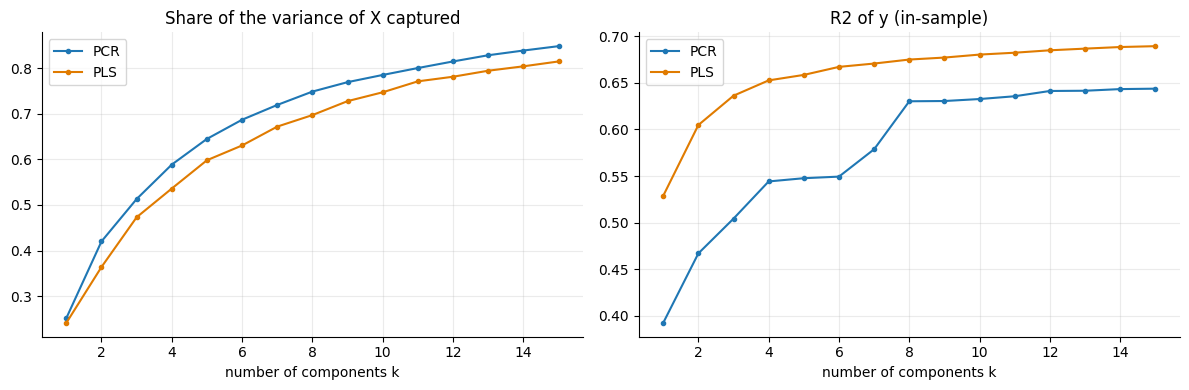

In [15]:
K_SHOW = 15
Zp = pls_det["Z"]; Pp = pls_det["P"]
X_var_PCR = np.cumsum(d**2)[:K_SHOW] / np.sum(d**2)
X_var_PLS = np.cumsum((Zp**2).sum(0) * (Pp**2).sum(0))[:K_SHOW] / np.sum(standardized_X**2)
R2 = lambda B: 1 - ((centered_Y[:, None] - standardized_X @ B) ** 2).sum(0) / (centered_Y @ centered_Y)

comparison = pd.DataFrame({"k": range(1, K_SHOW + 1),
                           "X captured - PCR": X_var_PCR, "X captured - PLS": X_var_PLS,
                           "R2 of y - PCR": R2(B_pcr[:, :K_SHOW]), "R2 of y - PLS": R2(B_pls[:, :K_SHOW])})
print(comparison.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(comparison.k, comparison["X captured - PCR"], "-o", ms=3, color=C_PCR, label="PCR")
ax[0].plot(comparison.k, comparison["X captured - PLS"], "-o", ms=3, color=C_PLS, label="PLS")
ax[0].set(title="Share of the variance of X captured", xlabel="number of components k"); ax[0].legend()
ax[1].plot(comparison.k, comparison["R2 of y - PCR"], "-o", ms=3, color=C_PCR, label="PCR")
ax[1].plot(comparison.k, comparison["R2 of y - PLS"], "-o", ms=3, color=C_PLS, label="PLS")
ax[1].set(title="R2 of y (in-sample)", xlabel="number of components k"); ax[1].legend()
plt.tight_layout(); plt.show()

Cosine between the first PCA direction and the first PLS direction: 0.904 (1 = same direction)
|Correlation| with y: first principal component = 0.626, first PLS component = 0.727

Largest coefficients of the first PCA direction (v1):
medFamInc          -0.183
medIncome          -0.182
PctKids2Par        -0.175
pctWInvInc         -0.174
PctPopUnderPov      0.173
PctFam2Par         -0.172
PctYoungKids2Par   -0.171
perCapInc          -0.169

Largest coefficients of the first PLS direction (w1):
PctKids2Par        -0.212
PctIlleg            0.212
PctFam2Par         -0.203
racePctWhite       -0.197
PctYoungKids2Par   -0.192
PctTeen2Par        -0.190
racepctblack        0.182
pctWInvInc         -0.166


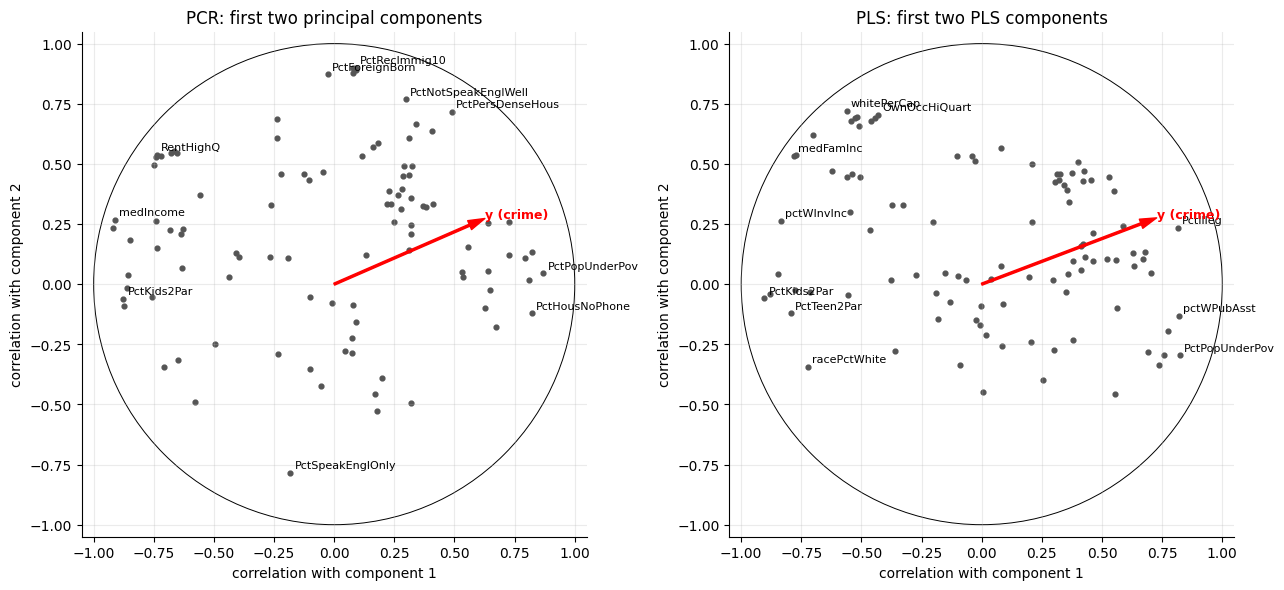

In [16]:
# First direction of each method: PCA eigenvector v1 vs PLS weight w1
v1 = V[:, 0] * np.sign(V[:, 0] @ w1)              # same sign for the comparison
cosine = v1 @ w1 / (np.linalg.norm(v1) * np.linalg.norm(w1))
z_pca1 = standardized_X @ v1
print(f"Cosine between the first PCA direction and the first PLS direction: {cosine:.3f} (1 = same direction)")
print(f"|Correlation| with y: first principal component = {abs(np.corrcoef(z_pca1, centered_Y)[0, 1]):.3f}, "
      f"first PLS component = {abs(np.corrcoef(z1, centered_Y)[0, 1]):.3f}")

top = lambda v, m=8: pd.Series(v, index=FEATURES).reindex(pd.Series(v, index=FEATURES).abs().sort_values(ascending=False).index).head(m)
print("\nLargest coefficients of the first PCA direction (v1):"); print(top(v1).round(3).to_string())
print("\nLargest coefficients of the first PLS direction (w1):"); print(top(w1).round(3).to_string())

# Correlation circles side by side: PCA (PC1, PC2) and PLS (z1, z2)
z2 = pls_det["Z"][:, 1]
corr_with = lambda z: np.array([np.corrcoef(standardized_X[:, j], z)[0, 1] for j in range(p)])
fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))
s1, s2 = np.sign(np.corrcoef(z_pca1, centered_Y)[0, 1]), 1.0
c_pc1, c_pc2 = corr_with(s1 * z_pca1), corr_with(standardized_X @ V[:, 1])
corr_circle(ax[0], c_pc1, c_pc2, [np.corrcoef(s1 * z_pca1, centered_Y)[0, 1], np.corrcoef(standardized_X @ V[:, 1], centered_Y)[0, 1]],
            "PCR: first two principal components")
corr_circle(ax[1], corr_with(z1), corr_with(z2), [np.corrcoef(z1, centered_Y)[0, 1], np.corrcoef(z2, centered_Y)[0, 1]],
            "PLS: first two PLS components")
ax[0].set(xlabel="correlation with component 1", ylabel="correlation with component 2")
ax[1].set(xlabel="correlation with component 1", ylabel="correlation with component 2")
plt.tight_layout(); plt.show()

**Reading (Section 8).**

- **PCR captures more of $X$, PLS explains more of $y$** — each method wins on its own criterion. With one component, PCR captures
  25 % of the variance of $X$ against 24 % for PLS, but explains only **39 %** of the variance of $y$ against **53 %** for PLS.
  PLS reaches $R^2 \approx 0.65$ with 4 components; PCR is still below that level with 15 components.
- **The first directions are close but not identical** (cosine 0.90). The first principal component is an **income / poverty axis**
  (`medFamInc`, `medIncome`, `PctPopUnderPov`): it is the main way in which communities differ, whatever the crime rate.
  The first PLS component gives more weight to the variables most correlated with crime: **family structure** (`PctKids2Par`, `PctIlleg`)
  and **race percentages**. It is more correlated with $y$ (0.73 vs 0.63).
- On the correlation circles, the red arrow ($y$) is longer and better aligned with the first axis for PLS: the PLS plane is "turned towards" $y$.

---
# Part III — Honest comparison of the predictions

## 9. How we validate: cross-validation by **groups of states**

### 9.1 Why not an ordinary (random) cross-validation?

Communities of the **same state** share the same laws, police organisation, economy and reporting practices. If two communities of the
same state end up one in the training sample and one in the test sample, the model can "recognise" the state and the test error
is too optimistic. We want to know how well the model predicts **for states it has never seen**.

So we never cut *inside* a state: **all the communities of a state are always on the same side.** This is done with `GroupKFold`
(scikit-learn), with `groups = state`.

### 9.2 What "5-fold cross-validation by states" means exactly

- The **46 states** are distributed into **5 folds**. It is **not** "5 states": each fold contains **several states** (between 8 and 10 here).
- `GroupKFold` balances the folds by **number of communities** (≈ 400 each), not by number of states: a fold with a big state
  (e.g. California, ~280 communities) contains fewer states than a fold made of small states.
- Each fold is used **once as validation/test set**: the model is fitted on the communities of the 4 other folds (36 to 38 states, ≈ 1 600
  communities) and evaluated on the ≈ 9 states it has never seen. We get 5 errors, and we pool them.

The table below shows the actual composition of the 5 folds.

In [17]:
STATE_ABBR = {1: "AL", 2: "AK", 4: "AZ", 5: "AR", 6: "CA", 8: "CO", 9: "CT", 10: "DE", 11: "DC", 12: "FL", 13: "GA", 15: "HI",
              16: "ID", 17: "IL", 18: "IN", 19: "IA", 20: "KS", 21: "KY", 22: "LA", 23: "ME", 24: "MD", 25: "MA", 26: "MI",
              27: "MN", 28: "MS", 29: "MO", 30: "MT", 31: "NE", 32: "NV", 33: "NH", 34: "NJ", 35: "NM", 36: "NY", 37: "NC",
              38: "ND", 39: "OH", 40: "OK", 41: "OR", 42: "PA", 44: "RI", 45: "SC", 46: "SD", 47: "TN", 48: "TX", 49: "UT",
              50: "VT", 51: "VA", 53: "WA", 54: "WV", 55: "WI", 56: "WY"}

def describe_folds(folds, groups_):
    rows = []
    for f, (tr, te) in enumerate(folds, start=1):
        st = pd.Series(groups_[te]).value_counts()
        rows.append({"fold": f, "states in the fold": len(st), "communities in the fold": len(te),
                     "communities used for fitting": len(tr),
                     "states (number of communities)": ", ".join(f"{STATE_ABBR.get(int(s), s)} ({c})" for s, c in st.items())})
    return pd.DataFrame(rows)

X_np = X.to_numpy(float)
y_np = Y.to_numpy(float)
outer_folds = list(GroupKFold(n_splits=N_FOLDS).split(X_np, y_np, groups))

pd.set_option("display.max_colwidth", 200)
describe_folds(outer_folds, groups)

,fold,states in the fold,communities in the fold,communities used for fitting,states (number of communities)
0,1,8,399,1595,"CA (278), OK (36), RI (26), LA (22), AZ (20), SD (9), ID (7), DC (1)"
1,2,9,399,1595,"NJ (211), IN (48), MO (42), VA (33), KY (26), NH (21), NM (10), MN (7), DE (1)"
2,3,10,400,1594,"TX (156), CT (69), NC (46), GA (37), OR (31), UT (24), MS (19), ND (8), WY (7), AK (3)"
3,4,9,398,1596,"MA (121), FL (90), NY (46), AL (43), TN (35), CO (25), IA (20), WV (14), VT (4)"
4,5,10,398,1596,"OH (109), PA (101), WI (60), WA (40), SC (28), AR (25), ME (17), MD (12), NV (5), KS (1)"


### 9.3 The modelling functions used in Parts III–V

To avoid any leakage, **everything is learnt on the training communities only**: the median used to fill the missing value,
the means and standard deviations used to standardize, the components, the coefficients. The test communities are only standardized
with the training means/standard deviations and then predicted.

`fit_all` fits, on one training sample, the whole "path" of each method:
- **PCR** for $k = 1..40$ (Section 6), **PLS** for $k = 1..40$ (Section 7),
- **Ridge** for every $\lambda$ of the grid, with the SVD formula of the course (slide 70): $\hat\beta^{RIDGE}_\lambda = V(D^2+\lambda I)^{-1}DU'y$,
- **OLS** (= PCR or PLS with all components),
- the **mean** of $y$ (the naive prediction that every model must beat).

Error measures (as in the course): **RMSE** $=\sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2}$ (called RMSFE in the course) and
**MAD** $=\frac{1}{n}\sum|y_i-\hat y_i|$. The response is in [0, 1], so an RMSE of 0.15 means a typical error of 0.15 on that scale.

In [18]:
def ridge_path(Xs, yc, lambdas):
    # Ridge coefficients for every lambda (p x L), course formula: V (D^2 + lambda I)^-1 D U' y
    U, d, V_t = svd(Xs, full_matrices=False)
    Uy = U.T @ yc
    return V_t.T @ (d[:, None] * Uy[:, None] / (d[:, None] ** 2 + lambdas[None, :]))

def fit_all(X_train, y_train, k_max=K_MAX, lambdas=LAMBDAS):
    # Learn everything on the training sample only
    med = np.nanmedian(X_train, axis=0)
    X_train = np.where(np.isnan(X_train), med, X_train)
    mean_X, std_X = X_train.mean(0), X_train.std(0)
    std_X[std_X == 0] = 1.0
    Xs = (X_train - mean_X) / std_X
    mean_Y = y_train.mean()
    yc = y_train - mean_Y
    k_max = min(k_max, Xs.shape[1], Xs.shape[0] - 1)
    return {"med": med, "mean_X": mean_X, "std_X": std_X, "mean_Y": mean_Y,
            "PCR": pcr_path(Xs, yc, k_max), "PLS": pls_path(Xs, yc, k_max),
            "Ridge": ridge_path(Xs, yc, lambdas), "OLS": np.linalg.lstsq(Xs, yc, rcond=None)[0][:, None]}

def predict_all(model, X_new):
    # Predictions for every method and every hyperparameter (one column each)
    X_new = np.where(np.isnan(X_new), model["med"], X_new)
    Xs = (X_new - model["mean_X"]) / model["std_X"]
    out = {m: model["mean_Y"] + Xs @ model[m] for m in ("PCR", "PLS", "Ridge", "OLS")}
    out["Mean"] = np.full((len(X_new), 1), model["mean_Y"])
    return out

def rmse(y, yhat): return float(np.sqrt(np.mean((y - yhat) ** 2)))
def mad(y, yhat): return float(np.mean(np.abs(y - yhat)))

def cv_curves(X_tr, y_tr, g_tr, n_folds=N_FOLDS):
    # Grouped K-fold cross-validation on a training sample: pooled RMSE for every method and hyperparameter
    folds = list(GroupKFold(n_splits=n_folds).split(X_tr, y_tr, g_tr))
    sse = {}
    for tr, va in folds:
        pred = predict_all(fit_all(X_tr[tr], y_tr[tr]), X_tr[va])
        for m, P in pred.items():
            sse[m] = sse.get(m, 0) + ((y_tr[va][:, None] - P) ** 2).sum(0)
    return {m: np.sqrt(s / len(y_tr)) for m, s in sse.items()}, folds

def choose(cv):
    # Hyperparameters chosen by cross-validation (+ the most parsimonious k within 2 % of the best CV error)
    out = {"k_PCR": int(np.argmin(cv["PCR"])) + 1, "k_PLS": int(np.argmin(cv["PLS"])) + 1,
           "lambda_Ridge": float(LAMBDAS[np.argmin(cv["Ridge"])])}
    for m in ("PCR", "PLS"):
        out["k_" + m + "_parsimonious"] = int(np.argmax(cv[m] <= 1.02 * cv[m].min())) + 1
    return out

print("Functions ready.")

Functions ready.


## 10. One complete example: fold 1 as test set

Before repeating it 5 times, we go through **one** split in detail. The test set is **fold 1** of Section 9.2
(its states are never used for fitting nor for choosing $k$). The procedure is the one of the course (`Ridge_Credit.ipynb`:
choose the hyperparameter on the training sample, then forecast the test sample), with a grouped cross-validation:

1. **Training sample** = the 4 other folds. Inside it, we run a new **5-fold cross-validation by states** (the training states are
   again split into 5 groups) to compute the CV error of every $k$ (PCR, PLS) and every $\lambda$ (ridge).
2. We keep the $k$ / $\lambda$ with the **lowest CV error**.
3. We refit each method on the whole training sample with that $k$ / $\lambda$ and **forecast the test states**.

In [19]:
train_idx, test_idx = outer_folds[0]
X_train, y_train, g_train = X_np[train_idx], y_np[train_idx], groups[train_idx]
X_test, y_test = X_np[test_idx], y_np[test_idx]
print(f"Training sample: {len(train_idx)} communities from {len(np.unique(g_train))} states")
print(f"Test sample    : {len(test_idx)} communities from {len(np.unique(groups[test_idx]))} states:",
      ", ".join(sorted(STATE_ABBR.get(int(s), str(s)) for s in np.unique(groups[test_idx]))))

# Step 1: grouped 5-fold cross-validation INSIDE the training sample
cv, inner_folds = cv_curves(X_train, y_train, g_train)
print("\nInner cross-validation folds (built from the training states only):")
describe_folds(inner_folds, g_train)[["fold", "states in the fold", "communities in the fold"]]

Training sample: 1595 communities from 38 states
Test sample    : 399 communities from 8 states: AZ, CA, DC, ID, LA, OK, RI, SD

Inner cross-validation folds (built from the training states only):


,fold,states in the fold,communities in the fold
0,1,6,319
1,2,7,320
2,3,8,319
3,4,8,319
4,5,9,318


k chosen for PCR: 8 (most parsimonious k within 2% of the best: 8)
k chosen for PLS: 4 (most parsimonious k within 2% of the best: 3)
lambda chosen for Ridge: 731.82


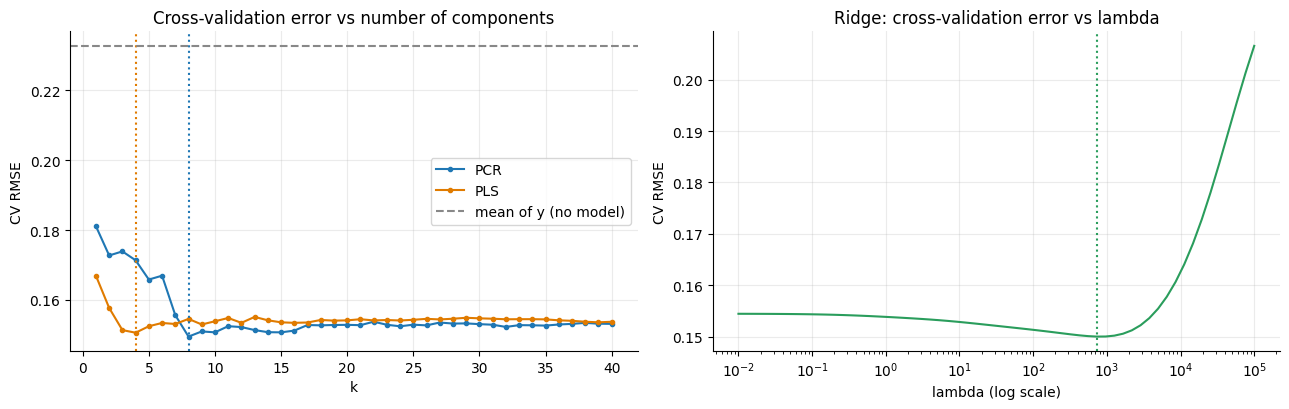

In [20]:
# Step 2: choice of the hyperparameters
sel = choose(cv)
print(f"k chosen for PCR: {sel['k_PCR']} (most parsimonious k within 2% of the best: {sel['k_PCR_parsimonious']})")
print(f"k chosen for PLS: {sel['k_PLS']} (most parsimonious k within 2% of the best: {sel['k_PLS_parsimonious']})")
print(f"lambda chosen for Ridge: {sel['lambda_Ridge']:.2f}")

ks = np.arange(1, K_MAX + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(ks, cv["PCR"], "-o", ms=3, color=C_PCR, label="PCR")
ax[0].plot(ks, cv["PLS"], "-o", ms=3, color=C_PLS, label="PLS")
ax[0].axvline(sel["k_PCR"], color=C_PCR, ls=":"); ax[0].axvline(sel["k_PLS"], color=C_PLS, ls=":")
ax[0].axhline(cv["Mean"][0], color=C_MEAN, ls="--", label="mean of y (no model)")
ax[0].set(title="Cross-validation error vs number of components", xlabel="k", ylabel="CV RMSE"); ax[0].legend()
ax[1].plot(LAMBDAS, cv["Ridge"], color=C_RIDGE); ax[1].axvline(sel["lambda_Ridge"], color=C_RIDGE, ls=":")
ax[1].set(xscale="log", title="Ridge: cross-validation error vs lambda", xlabel="lambda (log scale)", ylabel="CV RMSE")
plt.tight_layout(); plt.show()

In [21]:
# Step 3: refit on the whole training sample and forecast the test states
model = fit_all(X_train, y_train)
pred = predict_all(model, X_test)
forecasts = {"Mean of y": pred["Mean"][:, 0], "OLS (all 100 predictors)": pred["OLS"][:, 0],
             f"PCR (k={sel['k_PCR']})": pred["PCR"][:, sel["k_PCR"] - 1],
             f"PLS (k={sel['k_PLS']})": pred["PLS"][:, sel["k_PLS"] - 1],
             f"Ridge (lambda={sel['lambda_Ridge']:.1f})": pred["Ridge"][:, int(np.argmin(cv["Ridge"]))]}
pd.DataFrame({"RMSE": {m: rmse(y_test, f) for m, f in forecasts.items()},
              "MAD": {m: mad(y_test, f) for m, f in forecasts.items()}}).round(4)

,RMSE,MAD
Mean of y,0.2419,0.1716
OLS (all 100 predictors),0.1539,0.1082
PCR (k=8),0.1546,0.1084
PLS (k=4),0.1475,0.1024
Ridge (lambda=731.8),0.1483,0.1020


**Reading (Section 10).**

- The test fold contains 8 states (California, Oklahoma, Rhode Island, Louisiana, Arizona, South Dakota, Minnesota, DC), never used for fitting.
- The CV curves show the bias–variance trade-off of the course: with too few components the model is too simple (high error), then the error
  goes down and becomes flat. **PLS reaches its minimum with 4 components, PCR needs 8** — the PCR curve has "steps", because some
  principal components carry almost no information about $y$ and adding them does not help.
- On this fold, PLS (RMSE 0.148) and ridge (0.149) do slightly better than PCR (0.155) and OLS (0.155). All models are far better than
  predicting the mean of $y$ (0.243): they remove about 40 % of the error. One fold is only one draw — Section 11 repeats this on the 5 folds.

## 11. The full comparison: repeat for the 5 folds of states (nested cross-validation)

One test fold is only one draw: with another set of states the ranking could change. So we repeat Section 10 for **each of the 5 folds**:
each fold is the test set once, and the $k$ / $\lambda$ are always chosen by an inner grouped cross-validation on the 4 other folds.
This is called a **nested cross-validation**:

- **outer loop** (5 folds of states) → measures the prediction error on unseen states;
- **inner loop** (5 folds of the training states) → chooses the hyperparameters.

Every community is predicted exactly once, by a model that never saw its state. We report the error per fold and the pooled error over
the 1 994 communities.

In [22]:
def nested_cv(X_, y_, g_, outer=None, verbose=True):
    outer = outer if outer is not None else list(GroupKFold(n_splits=N_FOLDS).split(X_, y_, g_))
    rows, all_pred, test_curves = [], {}, []
    for f, (tr, te) in enumerate(outer, start=1):
        cv_f, _ = cv_curves(X_[tr], y_[tr], g_[tr])
        s = choose(cv_f)
        P = predict_all(fit_all(X_[tr], y_[tr]), X_[te])
        fc = {"Mean": P["Mean"][:, 0], "OLS": P["OLS"][:, 0], "PCR": P["PCR"][:, s["k_PCR"] - 1],
              "PLS": P["PLS"][:, s["k_PLS"] - 1], "Ridge": P["Ridge"][:, int(np.argmin(cv_f["Ridge"]))]}
        row = {"fold": f, "test states": len(np.unique(g_[te])), "test communities": len(te),
               "k PCR": s["k_PCR"], "k PLS": s["k_PLS"], "k PCR (pars.)": s["k_PCR_parsimonious"],
               "k PLS (pars.)": s["k_PLS_parsimonious"], "lambda Ridge": round(s["lambda_Ridge"], 1)}
        row.update({f"RMSE {m}": rmse(y_[te], v) for m, v in fc.items()})
        rows.append(row)
        for m, v in fc.items():
            all_pred.setdefault(m, np.empty(len(y_)))[te] = v
        test_curves.append({m: np.sqrt(((y_[te][:, None] - P[m]) ** 2).mean(0)) for m in ("PCR", "PLS")} | {"cv_" + m: cv_f[m] for m in ("PCR", "PLS")})
    table = pd.DataFrame(rows)
    pooled = pd.DataFrame({"RMSE": {m: rmse(y_, v) for m, v in all_pred.items()},
                           "MAD": {m: mad(y_, v) for m, v in all_pred.items()}})
    return table, pooled, test_curves

table_all, pooled_all, curves_all = nested_cv(X_np, y_np, groups, outer=outer_folds)
print("Per fold (each fold = several states never seen by the model):")
print(table_all.round(4).to_string(index=False))
print("\nPooled over the 1 994 communities:")
print(pooled_all.loc[["Mean", "OLS", "PCR", "PLS", "Ridge"]].round(4).to_string())

Per fold (each fold = several states never seen by the model):
 fold  test states  test communities  k PCR  k PLS  k PCR (pars.)  k PLS (pars.)  lambda Ridge  RMSE Mean  RMSE OLS  RMSE PCR  RMSE PLS  RMSE Ridge
    1            8               399      8      4              8              3         731.8     0.2419    0.1539    0.1546    0.1475      0.1483
    2            9               399     25      4             11              4         731.8     0.2169    0.1222    0.1175    0.1178      0.1161
    3           10               400     40     18             12              5          36.3     0.2081    0.1632    0.1619    0.1633      0.1601
    4            9               398     16      2              9              2         961.7     0.2715    0.1724    0.1791    0.1873      0.1778
    5           10               398     17      5              8              2         731.8     0.2363    0.1339    0.1319    0.1292      0.1334

Pooled over the 1 994 communities:
         RMSE

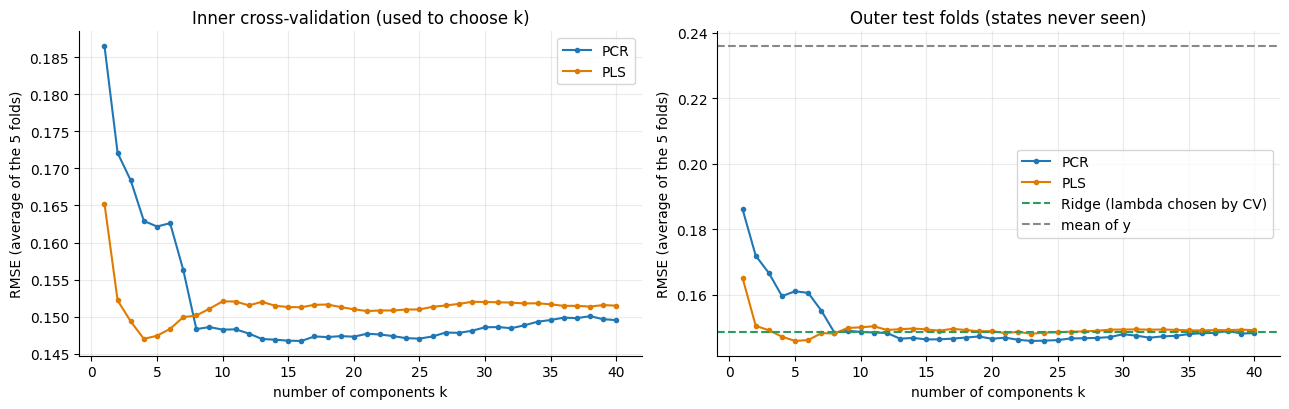

The right panel is shown for illustration only: the test folds were never used to choose k.


In [23]:
mean_curve = lambda key: np.mean([c[key] for c in curves_all], axis=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, pre, title in zip(ax, ("cv_", ""), ("Inner cross-validation (used to choose k)", "Outer test folds (states never seen)")):
    a.plot(ks, mean_curve(pre + "PCR"), "-o", ms=3, color=C_PCR, label="PCR")
    a.plot(ks, mean_curve(pre + "PLS"), "-o", ms=3, color=C_PLS, label="PLS")
    if pre == "":
        a.axhline(pooled_all.loc["Ridge", "RMSE"], color=C_RIDGE, ls="--", label="Ridge (lambda chosen by CV)")
        a.axhline(pooled_all.loc["Mean", "RMSE"], color=C_MEAN, ls="--", label="mean of y")
    a.set(title=title, xlabel="number of components k", ylabel="RMSE (average of the 5 folds)"); a.legend()
plt.tight_layout(); plt.show()
print("The right panel is shown for illustration only: the test folds were never used to choose k.")

## 12. What Part III tells us

1. **Same accuracy.** Over the 1 994 communities (each one predicted by a model that never saw its state), the RMSE is 0.151 for PCR,
   0.152 for PLS, 0.150 for ridge and 0.151 for OLS, against 0.237 for the mean. The differences between the four models
   (≈ 0.001–0.002) are tiny compared with the differences between folds (from 0.12 to 0.19): **no method is clearly more accurate.**
2. **PLS needs far fewer components.** PLS chooses 2 to 5 components (4 on average), PCR 8 to 25 (about 19 on average). This is the
   practical consequence of Section 8: PLS components are built for predicting $y$, so a few of them are enough.
3. **Why is OLS not worse here?** With $n \approx 1\,600$ training communities for $p = 100$ predictors, OLS is not in the "p close to n"
   situation where its variance explodes. The multicollinearity mostly makes the **coefficients** unstable (Section 14), not the
   predictions. The advantage of PCR/PLS here is parsimony and stability, not accuracy.
4. **Which states are hard?** Fold 4 (Massachusetts, Florida, North Carolina, …) has the largest error for every method: the model learnt on
   the other states transfers less well there. This is exactly what an ordinary random CV would have hidden.
5. This matches ISLR (6.3.2): *"in practice PLS often performs no better than ridge regression or PCR"* — supervision reduces bias but can
   increase variance.

---
# Part IV — When and why do PCR and PLS differ?

## 13. Effect of the number of observations

The theory (ISLR 6.3.2) says that PLS, because it uses $y$ to build the components, **reduces the bias** but can **increase the variance**
(the components adapt to the noise of $y$ in the training sample). The variance problem is larger when the training sample is small.

Experiment: we keep a **fixed test set** (fold 1, unseen states) and fit the models on random sub-samples of the training sample of size
$n = 100, 200, 400, 800$ and on the full training sample. For each size, 10 repetitions; each time $k$ and $\lambda$ are chosen by grouped
cross-validation on the sub-sample.

      k PCR  k PLS     PCR     PLS   Ridge    Mean  PLS better than PCR by
n                                                                         
100    14.1    1.9  0.1861  0.1912  0.1666  0.2442                 -0.0274
200    14.0    3.2  0.1616  0.1656  0.1568  0.2438                 -0.0250
400    15.0    3.7  0.1562  0.1599  0.1579  0.2427                 -0.0232
800    10.7    3.5  0.1517  0.1540  0.1488  0.2426                 -0.0153
1595    8.0    4.0  0.1546  0.1475  0.1483  0.2419                  0.0464


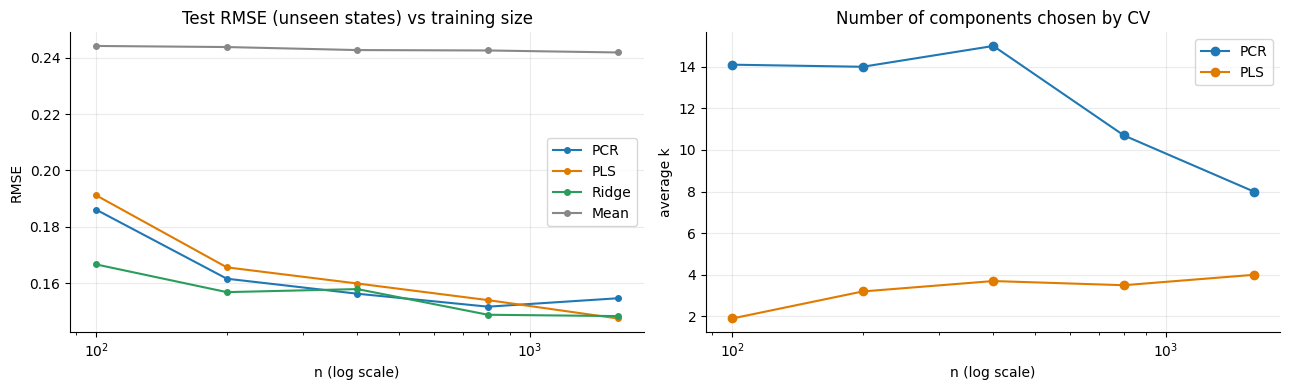

In [24]:
rows = []
for n_sub in [100, 200, 400, 800, len(train_idx)]:
    n_rep = 10 if n_sub < len(train_idx) else 1
    for rep in range(n_rep):
        rng = np.random.default_rng(1000 * rep + n_sub)
        sub = rng.choice(len(train_idx), size=n_sub, replace=False)
        Xs_, ys_, gs_ = X_train[sub], y_train[sub], g_train[sub]
        cv_s, _ = cv_curves(Xs_, ys_, gs_)
        s = choose(cv_s)
        P = predict_all(fit_all(Xs_, ys_), X_test)
        rows.append({"n": n_sub, "k PCR": s["k_PCR"], "k PLS": s["k_PLS"],
                     "PCR": rmse(y_test, P["PCR"][:, s["k_PCR"] - 1]), "PLS": rmse(y_test, P["PLS"][:, s["k_PLS"] - 1]),
                     "Ridge": rmse(y_test, P["Ridge"][:, int(np.argmin(cv_s["Ridge"]))]), "Mean": rmse(y_test, P["Mean"][:, 0])})
size_res = pd.DataFrame(rows).groupby("n").mean()
size_res["PLS better than PCR by"] = (size_res["PCR"] - size_res["PLS"]) / size_res["PCR"]
print(size_res.round(4).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for m, c in (("PCR", C_PCR), ("PLS", C_PLS), ("Ridge", C_RIDGE), ("Mean", C_MEAN)):
    ax[0].plot(size_res.index, size_res[m], "-o", ms=4, color=c, label=m)
ax[0].set(xscale="log", title="Test RMSE (unseen states) vs training size", xlabel="n (log scale)", ylabel="RMSE"); ax[0].legend()
ax[1].plot(size_res.index, size_res["k PCR"], "-o", color=C_PCR, label="PCR")
ax[1].plot(size_res.index, size_res["k PLS"], "-o", color=C_PLS, label="PLS")
ax[1].set(xscale="log", title="Number of components chosen by CV", xlabel="n (log scale)", ylabel="average k"); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading (Section 13).**

- **Small samples: PLS is slightly worse than PCR** (by 1 % to 5.5 % of RMSE for $n$ between 100 and 800), and ridge is the best or
  close to the best. This is the variance cost of supervision announced by the theory: with few communities, the PLS components
  follow the noise of $y$ in the training sample.
- **Full training sample: PLS is better** (by 4.5 % on this test fold, single draw).
- Whatever $n$, **PLS keeps 3–4 components**, while PCR uses 8–16: PLS is always the more parsimonious of the two.

## 14. Interpreting the fitted models

We fit the three methods on the whole sample, with the "parsimonious" $k$ chosen most often in Section 11 (median over the 5 folds) and
the median $\lambda$. The coefficients are on **standardized** predictors: a coefficient is the change of $y$ (on its [0, 1] scale) when
the predictor increases by one standard deviation, the others being fixed.

**Caution.** These are *associations* between characteristics of communities in 1990 and crime in 1995, not causal effects; and they
describe communities, not individuals (ecological fallacy).

In [25]:
k_pcr = int(table_all["k PCR (pars.)"].median())
k_pls = int(table_all["k PLS (pars.)"].median())
lam = float(table_all["lambda Ridge"].median())
coef = pd.DataFrame({f"PCR (k={k_pcr})": B_pcr[:, k_pcr - 1], f"PLS (k={k_pls})": B_pls[:, k_pls - 1],
                     f"Ridge (lambda={lam:.0f})": ridge_path(standardized_X, centered_Y, np.array([lam]))[:, 0],
                     "OLS": beta_OLS, "correlation with y": corr_with_Y.values}, index=FEATURES)
print("The 12 largest PLS coefficients (standardized predictors):")
print(coef.reindex(coef.iloc[:, 1].abs().sort_values(ascending=False).index).head(12).round(4).to_string())

n_wrong = lambda b: int(((np.sign(b) != np.sign(corr_with_Y.values)) & (np.abs(corr_with_Y.values) > 0.3)).sum())
print("\nNumber of predictors strongly correlated with y (|r| > 0.3) whose coefficient has the OPPOSITE sign of the correlation:")
print({c: n_wrong(coef[c].values) for c in coef.columns[:4]})
print("(like the cars2004 example of the slides: OLS coefficients can contradict the correlations; PCR and PLS much less)")

The 12 largest PLS coefficients (standardized predictors):
                  PCR (k=9)  PLS (k=3)  Ridge (lambda=732)     OLS  correlation with y
racepctblack         0.0180     0.0193              0.0266  0.0514              0.6313
PctIlleg             0.0154     0.0168              0.0240  0.0267              0.7380
racePctWhite        -0.0157    -0.0162             -0.0203 -0.0121             -0.6848
PctKids2Par         -0.0135    -0.0140             -0.0168 -0.0672             -0.7384
PctFam2Par          -0.0126    -0.0127             -0.0133  0.0039             -0.7067
PctTeen2Par         -0.0133    -0.0126             -0.0101 -0.0004             -0.6616
PctYoungKids2Par    -0.0122    -0.0117             -0.0122 -0.0067             -0.6661
TotalPctDiv          0.0122     0.0102              0.0064 -0.0957              0.5528
MalePctDivorce       0.0114     0.0102              0.0101  0.0793              0.5254
PctVacantBoarded     0.0111     0.0101              0.0105  0.0111     

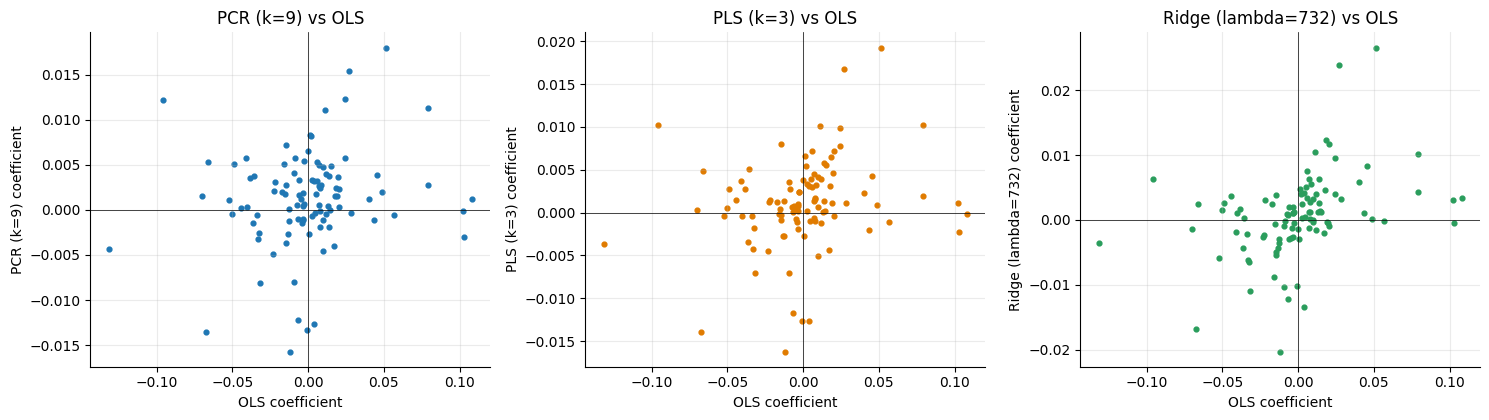

OLS coefficients spread over a much wider range: PCR, PLS and ridge all shrink them.
Range of coefficients: OLS [-0.132, 0.108] | PLS [-0.016, 0.019]


In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, col, c in zip(ax, coef.columns[:3], (C_PCR, C_PLS, C_RIDGE)):
    a.scatter(coef["OLS"], coef[col], s=12, color=c)
    a.axhline(0, color="k", lw=.5); a.axvline(0, color="k", lw=.5)
    a.set(xlabel="OLS coefficient", ylabel=f"{col} coefficient", title=f"{col} vs OLS")
plt.tight_layout(); plt.show()
print("OLS coefficients spread over a much wider range: PCR, PLS and ridge all shrink them.")
print(f"Range of coefficients: OLS [{coef['OLS'].min():.3f}, {coef['OLS'].max():.3f}] | "
      f"PLS [{coef.iloc[:, 1].min():.3f}, {coef.iloc[:, 1].max():.3f}]")

**Reading (Section 14).**

- **PCR and PLS give very similar coefficients** (same signs, same order of magnitude): the variables with the largest positive
  association with crime are `racepctblack` and `PctIlleg`; the largest negative ones are `racePctWhite` and the family-structure variables
  (`PctKids2Par`, `PctFam2Par`, …).
- **OLS coefficients are unstable.** They range from −0.13 to +0.11 (vs −0.016 to +0.019 for PLS) and **15 predictors strongly correlated
  with $y$ get an OLS coefficient of the opposite sign** (2 for PLS, 4 for PCR, 9 for ridge). Example: `TotalPctDiv` (% divorced) has a
  correlation of +0.55 with crime but an OLS coefficient of −0.096, while its near-duplicates `MalePctDivorce` and `FemalePctDiv` get
  large positive coefficients — OLS splits the same information between collinear variables in an arbitrary way. This is the
  *cars2004* phenomenon of the slides (slide 21), on real data.
- PCR and PLS spread the effect over all the correlated variables of a block, which gives coefficients that are easier to explain.

---
# Part V — Robustness

## 15. Without the race variables

The data contain four race percentages (`racepctblack`, `racePctWhite`, `racePctAsian`, `racePctHisp`). They are sensitive and they are
among the most correlated with $y$. We rerun the full nested cross-validation of Section 11 **without them**, to check that the
conclusions on PCR vs PLS do not depend on them. Note that other variables (income, family structure, immigration) remain partly
correlated with them (proxies).

In [27]:
race_cols = [c for c in FEATURES if re.match(r"(?i)^race", c)]
keep = [i for i, c in enumerate(FEATURES) if c not in race_cols]
print("Variables removed:", race_cols)

table_nr, pooled_nr, _ = nested_cv(X_np[:, keep], y_np, groups, outer=outer_folds)
print("\nPer fold, without the race variables:")
print(table_nr[["fold", "k PCR", "k PLS", "RMSE PCR", "RMSE PLS", "RMSE Ridge", "RMSE Mean"]].round(4).to_string(index=False))
print("\nPooled RMSE:")
print(pd.DataFrame({"all 100 predictors": pooled_all["RMSE"], "without race variables": pooled_nr["RMSE"]})
      .loc[["Mean", "OLS", "PCR", "PLS", "Ridge"]].round(4).to_string())

Variables removed: ['racepctblack', 'racePctWhite', 'racePctAsian', 'racePctHisp']

Per fold, without the race variables:
 fold  k PCR  k PLS  RMSE PCR  RMSE PLS  RMSE Ridge  RMSE Mean
    1     37     40    0.1566    0.1634      0.1586     0.2419
    2     24     24    0.1170    0.1201      0.1163     0.2169
    3     40     16    0.1635    0.1601      0.1581     0.2081
    4     21      5    0.1830    0.1777      0.1796     0.2715
    5     17      5    0.1386    0.1352      0.1367     0.2363

Pooled RMSE:
       all 100 predictors  without race variables
Mean               0.2360                  0.2360
OLS                0.1503                  0.1509
PCR                0.1506                  0.1534
PLS                0.1510                  0.1527
Ridge              0.1487                  0.1514


## 16. Stability: 20 other splits of the states

The 5 folds of Section 9 are one particular way of grouping the states. We now draw **20 random splits** where about 20 % of the states
form the test set (`GroupShuffleSplit`), and each time choose $k$ / $\lambda$ by grouped cross-validation on the remaining states.
If PLS were really better than PCR, it should win in most splits and by more than the split-to-split noise.

         PCR     PLS   Ridge    Mean    k PCR   k PLS
mean  0.1427  0.1421  0.1404  0.2223  21.9000  6.0500
std   0.0181  0.0182  0.0178  0.0202   7.9993  3.6631

PLS better than PCR in 8 of 20 splits; average difference PCR - PLS = +0.0007 (standard deviation 0.0029)


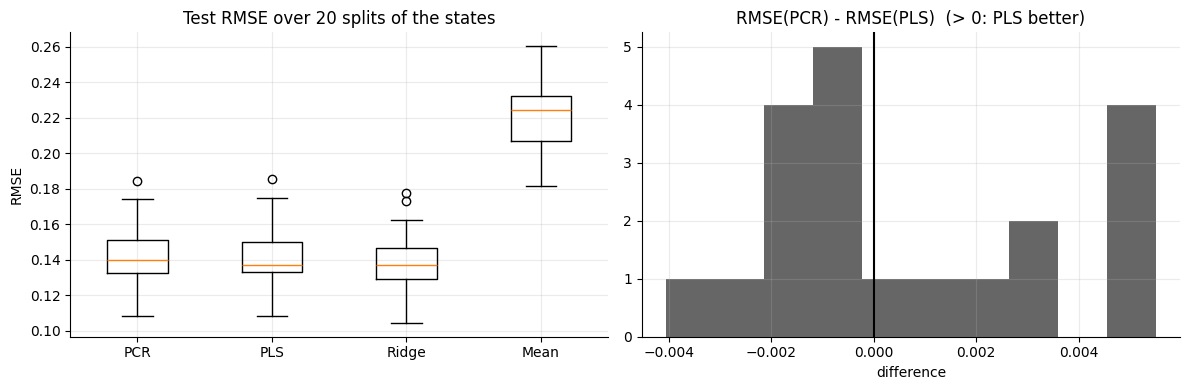

In [28]:
rows = []
for s in range(20):
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=s).split(X_np, y_np, groups))
    cv_s, _ = cv_curves(X_np[tr], y_np[tr], groups[tr])
    c = choose(cv_s)
    P = predict_all(fit_all(X_np[tr], y_np[tr]), X_np[te])
    rows.append({"split": s, "k PCR": c["k_PCR"], "k PLS": c["k_PLS"],
                 "PCR": rmse(y_np[te], P["PCR"][:, c["k_PCR"] - 1]), "PLS": rmse(y_np[te], P["PLS"][:, c["k_PLS"] - 1]),
                 "Ridge": rmse(y_np[te], P["Ridge"][:, int(np.argmin(cv_s["Ridge"]))]), "Mean": rmse(y_np[te], P["Mean"][:, 0]),
                 "OLS": rmse(y_np[te], P["OLS"][:, 0])})
splits = pd.DataFrame(rows)
splits["PCR - PLS"] = splits["PCR"] - splits["PLS"]
print(splits[["PCR", "PLS", "Ridge", "Mean", "k PCR", "k PLS"]].agg(["mean", "std"]).round(4).to_string())
print(f"\nPLS better than PCR in {(splits['PCR - PLS'] > 0).sum()} of 20 splits; "
      f"average difference PCR - PLS = {splits['PCR - PLS'].mean():+.4f} (standard deviation {splits['PCR - PLS'].std():.4f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].boxplot([splits["PCR"], splits["PLS"], splits["Ridge"], splits["Mean"]])
ax[0].set_xticks([1, 2, 3, 4], ["PCR", "PLS", "Ridge", "Mean"]); ax[0].set(title="Test RMSE over 20 splits of the states", ylabel="RMSE")
ax[1].hist(splits["PCR - PLS"], bins=10, color="#666"); ax[1].axvline(0, color="k")
ax[1].set(title="RMSE(PCR) - RMSE(PLS)  (> 0: PLS better)", xlabel="difference")
plt.tight_layout(); plt.show()

**Reading (Sections 15–16).**

- **Without the race variables** every method loses a little accuracy (PCR 0.151 → 0.155, PLS 0.152 → 0.158, ridge 0.150 → 0.153), the
  mean is unchanged. PLS loses the most and its choice of $k$ becomes unstable (from 2 to 40 components depending on the fold): the
  race variables were among the most correlated with $y$, so they shaped the first PLS components. Without them the information is
  scattered over more variables (income, family structure, immigration), partly acting as proxies. The ranking of the methods does
  not change: no method dominates.
- **Over 20 random splits of the states**, PLS beats PCR in 11 of 20 splits; the average difference (+0.0006) is about 5 times smaller
  than its standard deviation (0.0031). There is **no significant difference in accuracy** between PCR and PLS; ridge is marginally the
  best on average. PLS uses about 6 components on average, PCR about 23.

---
# Part VI — Conclusion

## 17. Summary table

In [29]:
summary = pd.DataFrame({
    "nested CV RMSE (5 folds of states)": pooled_all["RMSE"],
    "nested CV MAD": pooled_all["MAD"],
    "RMSE without race variables": pooled_nr["RMSE"],
    "mean RMSE over 20 random splits": splits[["PCR", "PLS", "Ridge", "Mean", "OLS"]].mean(),
}).loc[["Mean", "OLS", "PCR", "PLS", "Ridge"]]
summary["number of components (average over the 5 folds)"] = [np.nan, 100, table_all["k PCR"].mean(), table_all["k PLS"].mean(), np.nan]
summary.round(4)

,nested CV RMSE (5 folds of states),nested CV MAD,RMSE without race variables,mean RMSE over 20 random splits,number of components (average over the 5 folds)
Mean,0.2360,0.1812,0.2360,0.2223,NaN
OLS,0.1503,0.1054,0.1509,0.1442,100.0
PCR,0.1506,0.1053,0.1534,0.1427,21.2
PLS,0.1510,0.1042,0.1527,0.1421,6.6
Ridge,0.1487,0.1023,0.1514,0.1404,NaN


## 18. Take-aways and limits

### Take-aways (for a non-expert reader)

1. **Same tool, different compass.** PCR and PLS both summarise 100 redundant variables by a few components and regress the response on
   them. PCR chooses its components by looking only at how communities differ (variance of $X$); PLS chooses them by looking at what
   is related to crime (covariance with $y$).
2. **Consequence: PLS needs far fewer components** (about 4 vs about 19 here). Its first component already explains 53 % of the
   variance of crime, against 39 % for the first principal component.
3. **But not better predictions.** On states never seen by the model, PCR, PLS, ridge and even OLS have practically the same error (RMSE ≈ 0.15
   on a [0, 1] scale, 37 % better than predicting the average). This is the usual empirical finding (ISLR): supervision lowers the bias,
   but adds variance.
4. **When PLS suffers.** With small training samples, or when the variables most related to $y$ are removed, PLS becomes less stable than
   PCR (its components adapt to the noise of $y$).
5. **Main practical benefit: parsimony and stable coefficients.** Compared with OLS, both methods avoid coefficients with absurd signs.
   PLS gives the most compact and the most "$y$-oriented" summary of the data.

### Limits

- **Old data**: 1990 census and 1995 crime figures; the relationships may have changed.
- **Normalized variables** (to [0, 1], with outliers clipped by the authors): coefficients cannot be read in natural units.
- **Associations, not causes**, and **at the community level, not the individual level** (ecological fallacy).
- **Selection**: the source excluded communities with missing crime data (many in the Midwest); the 22 police variables were dropped.
- **Sensitive variables**: race percentages are strongly associated with crime here because they are correlated with income, family
  structure and segregation; Section 15 shows that the comparison of the methods does not depend on them.
- **One data set, linear models**: the conclusions are specific to this data set; non-linear methods were not considered.

### References
- G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning*, Sections 6.3.1–6.3.2.
- G. Sanchez, *Partial Least Squares Regression*, slides (CC BY-SA 4.0).
- S. Hué, *Automatic Model Selection Methods*, AMSE — Chapter 1 (PCA) and Chapter 2 (ridge, PCR).
- M. Redmond, A. Baveja (2002), *A data-driven software tool for enabling cooperative information sharing among police departments*,
  European Journal of Operational Research; UCI Machine Learning Repository, *Communities and Crime* (CC BY 4.0).